# 03. Fintech campaign: two factors at once (2x2 factorial)

**The decision:** the fintech CRM team is about to fire an activation campaign and
has two levers on the table, each binary. First: offer cashback or not (factor A).
Second: send in the morning or in the evening (factor B). The business question is
not "which of the two do I test first", it is "how do I design a single experiment
that answers both at once, and also reveals whether they talk to each other".

A **2x2 factorial** design does exactly that: it measures both **main effects**
(how much cashback moves activation, how much send time moves it) **and the
interaction** (whether cashback pays off more when sent in the evening) in a single
experiment, on the same pool of users.

Supporting theory: [II. Designs](../../../docs/en/theory/02-designs.md) (topic 7)
and [III. Estimation](../../../docs/en/theory/03-estimation.md) (topic 12).


## The natural reflex (and why it is expensive)

You know the A/B test from the previous chapter, so the instinct is clear: run two.
One experiment for cashback (with versus without), another for send time (morning
versus evening). Each one clean, each one with its own t-test. It works, but it
charges you twice.

The first cost is **users**: two experiments consume twice the base, or split the
same base in half and lose power in each. The second is subtler and worse: two
isolated tests can **never** answer the interaction. The question "does cashback
pay off more when it lands in the evening?" simply does not exist in a
one-factor-at-a-time design; you measured each lever with the other "averaged out",
and the synergy between them stays invisible.

The factorial solves both at once: on a single base, it delivers the two main
effects **and** the interaction, for the price of one experiment.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd


def _find_data():
    """Locate examples/use_cases/data whether run from the notebook or the root."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        for cand in (base / "data", base / "examples" / "use_cases" / "data"):
            if (cand / "ecommerce_checkout.csv").exists():
                return cand
    raise FileNotFoundError("Could not locate examples/use_cases/data")


DATA = _find_data()

df = pd.read_csv(DATA / "fintech_crm.csv")
print(df.shape)
df.head()

(4000, 3)


,customer_id,tenure_months,noise
0,1,25,4.014
1,2,13,-0.208
2,3,52,-1.170
3,4,25,-7.004
4,5,29,0.865


## The factorial design and the outcome

`FactorialDesign(factors=["cashback", "send_time"], n_per_cell=1000)` draws the
2^2 = 4 cells (every combination of the two factors) with equal size, one thousand
users per cell. That is the skeleton of the experiment.

The outcome (activations) is simulated from the assigned factors, with coefficients
that **we know**, in a {0,1} coding:

`activations = 30 + 4*cashback + 2*send_time + 3*(cashback*send_time) + noise`.

Here lies a subtlety the theory (topic 12) spells out: the simulation's {0,1}
coding is **not** the same scale as the ±1 contrasts the estimator uses. Under that
translation, the estimated main effect becomes `b + half the interaction`. So what
we expect to recover is not the raw coefficients, it is:
cashback `4 + 3/2 = 5.5`, send_time `2 + 3/2 = 3.5`, interaction `3/2 = 1.5`. Keep
those three numbers, they are the answer key.


In [2]:
from skxperiments.core.assignment import FactorialAssignment
from skxperiments.design.factorial import FactorialDesign

design = FactorialDesign(factors=["cashback", "send_time"], n_per_cell=1000, seed=303)
assignment = design.randomize(df[["customer_id", "tenure_months"]].copy())

A = assignment.data_["cashback"].to_numpy()
B = assignment.data_["send_time"].to_numpy()
data = assignment.data_.copy()
data["activations"] = 30 + 4 * A + 2 * B + 3 * (A * B) + df["noise"].to_numpy()

assignment = FactorialAssignment(
    data=data, design=design, factor_cols=assignment.factor_cols,
    cell_sizes=assignment.cell_sizes_, seed=303,
)
assignment.data_.groupby(["cashback", "send_time"])["activations"].mean().round(2)

cashback  send_time
0         0            29.98
          1            32.12
1         0            33.98
          1            38.85
Name: activations, dtype: float64

In [3]:
from skxperiments.estimators.factorial_estimator import FactorialEstimator

result = FactorialEstimator(outcome_col="activations").fit(assignment).estimate()
expected = {"cashback": 5.5, "send_time": 3.5, "cashback:send_time": 1.5}
rows = []
for key, value in result.effects.items():
    name = ":".join(key)
    rows.append({"effect": name, "estimated": round(value, 3), "expected": expected[name]})
pd.DataFrame(rows)

,effect,estimated,expected
0,cashback,5.364,5.5
1,send_time,3.512,3.5
2,cashback:send_time,1.362,1.5


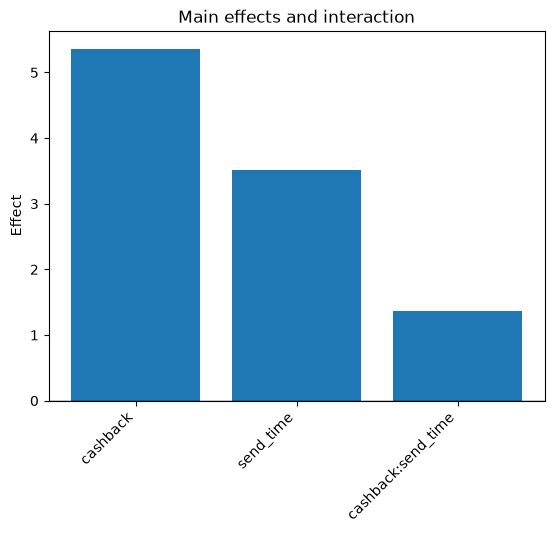

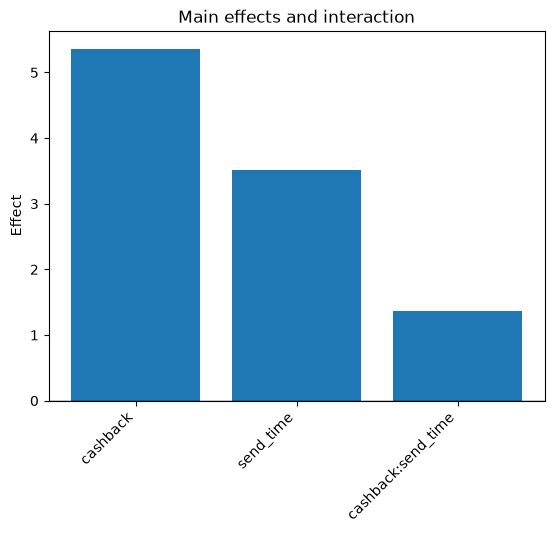

In [4]:
from skxperiments.reporting import plot_interaction

ax = plot_interaction(result)
ax.set_title("Main effects and interaction")
ax.figure

## The honest limit: v1 has no factorial inference

Notice what we did **not** print: confidence intervals or p-values for those
effects. That is not an oversight. In v1, the randomization and Neyman inference
paths **do not cover** factorial effects, and the library refuses to fabricate an
uncertainty number it cannot compute correctly.

This is a virtue, not a bug. Instead of quietly returning a wrong CI, it **fails
fast** and tells you exactly why. Let us trigger that failure on purpose, so you
see the message with your own eyes and learn to recognize it.


In [5]:
# The honest boundary: in v1, the randomization and Neyman inference paths do NOT
# cover factorial effects. The library fails fast with a clear message instead of
# returning a wrong number. This is a dev-stage limit, not a mistake on your part.
from skxperiments.inference import RandomizationTest, NeymanCI

for label, make in [
    ("RandomizationTest", lambda: RandomizationTest(
        estimator=FactorialEstimator(outcome_col="activations"), n_permutations=200, seed=0)),
    ("NeymanCI", lambda: NeymanCI(estimator=FactorialEstimator(outcome_col="activations"))),
]:
    try:
        make().fit(assignment).estimate()
        print(f"{label}: (no error)")
    except Exception as e:
        print(f"{label} -> {type(e).__name__}: {e}")

RandomizationTest -> DesignEstimatorMismatch: [RandomizationTest] expects CRDAssignment or BlockedAssignment but received FactorialAssignment.
NeymanCI -> DesignEstimatorMismatch: [NeymanCI] expects DifferenceInMeans or BlockedDifferenceInMeans but received FactorialEstimator. Suggestion: use DifferenceInMeans or BlockedDifferenceInMeans. CUPED and LinEstimator support is planned for a future sub-phase (see ROADMAP). instead.


## What to reach for (for now)

Those `DesignEstimatorMismatch` messages ("expects CRDAssignment ... received
FactorialAssignment"; "expects DifferenceInMeans ... received FactorialEstimator")
are the honest boundary of v1: the **point estimates** and the **interaction
picture** are trustworthy, but the **uncertainty** around them needs a tool the
library does not ship yet.

For now, to put confidence intervals on factorial effects you reach for something
Ana already knows. Two direct options: an `OLS` with an interaction term in
`statsmodels` (the coefficients and their CIs come for free), or a hand-rolled
**bootstrap** of each contrast. Factorial inference is on the roadmap for v2. This
is the dev-stage honesty that matters: use the library for the design and the point
estimates, and borrow your own tool for the CIs until it grows one.


## The decision, the limits, and the next step

All three effects recover close to expectation (about 5.5, 3.5, and 1.5). The
positive interaction confirms the hypothesis only a factorial could test: cashback
and evening send **reinforce each other**. Together, they deliver more than the sum
of the isolated effects.

**Recommendation:** combine both factors at the high level (cashback + evening). A
one-factor-at-a-time design would never reveal this synergy; it would hand you two
separate "yes" answers and hide the bonus of pairing them.

**Limits of this chapter:** (1) no factorial inference in v1, point estimates only;
(2) equal-cell 2^k factorials only; (3) `FactorialAssignment.treated_ids` /
`control_ids` are not implemented for factorial designs.

Next step:
[04. Re-randomization in logistics](04_logistics_rerandomization.ipynb).
